# Bell Pepper Leaf Disease Classification with CNN

This notebook trains a convolutional neural network to classify bell pepper
leaf images into two categories: bacterial spot, and healthy.
The dataset contains 2,475 labeled images.


In [1]:
# %pip install tensorflow matplotlib scikit-learn

### Import the dependencies

In [2]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt
import numpy as np

### Set dataset and training parameters

In [3]:
BATCH_SIZE=32
IMAGE_SIZE=(256, 256)
SEED=123
CHANNELS=3
EPOCHS=50

### Load potato leaf images

In [4]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "data",
    seed=SEED,
    shuffle=True,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
)

Found 2475 files belonging to 2 classes.


In [5]:
class_names = dataset.class_names
class_names

['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy']

In [6]:
N_CLASSES=len(class_names)
N_CLASSES

2

### Visualize sample images

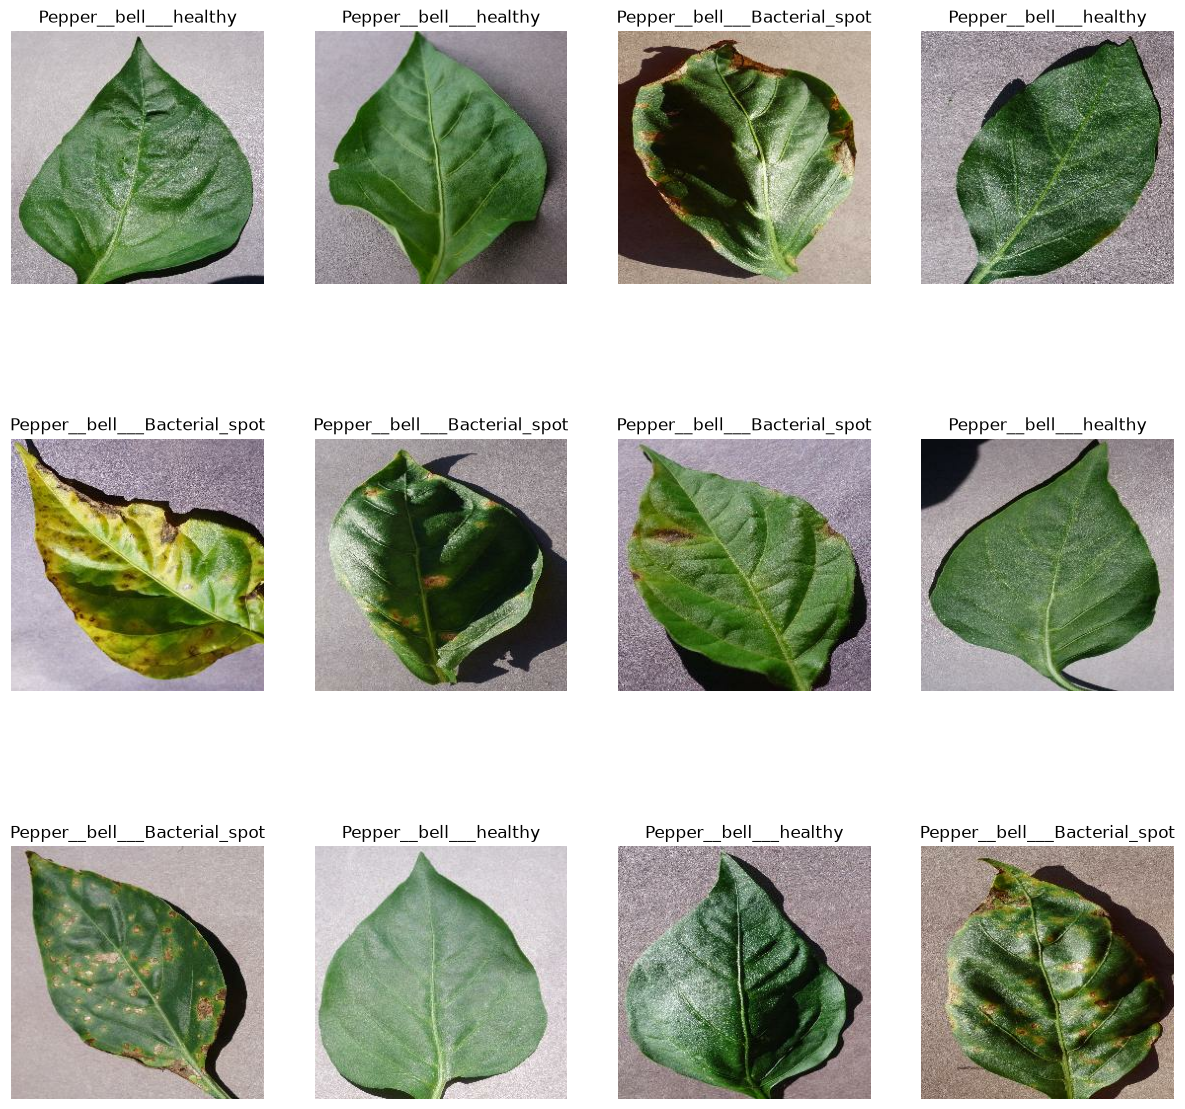

In [7]:
plt.figure(figsize=(15, 15))
for image_batch, label_batch in dataset.take(1):
    for i in range(12):
        plt.subplot(3, 4, i+1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(class_names[label_batch[i]])
        plt.axis("off")

### Split the dataset into Training, Validation, and Test Sets

In [8]:
def get_dataset_partition_tf(
    ds, train_split=0.8, val_split=0.1, test_split=0.1, shuffle=True, shuffle_size=10000
):
    assert (train_split + val_split + test_split) == 1
    ds_size = len(ds)

    if shuffle:
        ds = ds.shuffle(shuffle_size, seed=12)
    train_size = int(train_split * ds_size)
    val_size = int(val_split * ds_size)

    train_ds = ds.take(train_size)
    val_ds = ds.skip(train_size).take(val_size)
    test_ds = ds.skip(train_size).skip(val_size)

    return train_ds, val_ds, test_ds

In [9]:
train_ds, val_ds, test_ds = get_dataset_partition_tf(dataset)

In [10]:
len(train_ds) #Train batches

62

In [11]:
len(val_ds) #Val batches

7

In [12]:
len(test_ds) #Test batches

9

### Cache, Shuffle & prefetch the dataset

In [13]:
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = train_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

## Building the Model

### Resize and rescale images

In [14]:
resize_and_rescale = tf.keras.Sequential(
    [
        layers.Resizing(IMAGE_SIZE[0], IMAGE_SIZE[1]),
        layers.Rescaling(1.0 / 255),
    ],
    name="resize-and-rescale"
)

### Data augmentation

In [15]:
data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.2),
        layers.RandomZoom(0.1),
        layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
        layers.RandomBrightness(0.15),
        layers.RandomContrast(0.15),
    ],
    name="data-augmentation",
)

### Applying data augmentation to train dataset

In [16]:
train_ds = train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y)
).prefetch(buffer_size=tf.data.AUTOTUNE)

### Model Architecture

In [17]:
input_shape = IMAGE_SIZE + (CHANNELS,)
model = models.Sequential(
    [
        layers.Input(shape=input_shape),
        resize_and_rescale,
        layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
        layers.MaxPool2D((2, 2)),
        layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
        layers.MaxPool2D((2, 2)),
        layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
        layers.MaxPool2D((2, 2)),
        layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
        layers.MaxPool2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(N_CLASSES, activation="softmax"),
    ],
    name="bell-pepper-cnn",
)

model.summary()

Model: "bell-pepper-cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resize-and-rescale (Sequential) │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       401,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 430,242 (1.64 MB)

 Trainable params: 430,242 (1.64 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
### Compile the model

In [19]:
model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=["accuracy"],
)

In [20]:
### Train the model

In [21]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    verbose=1,
    epochs=EPOCHS,
)

Epoch 1/50


C:\Users\Dhool-AYESHA\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


62/62 ━━━━━━━━━━━━━━━━━━━━ 70s 1s/step - accuracy: 0.7616 - loss: 0.5158 - val_accuracy: 0.8370 - val_loss: 0.5158
Epoch 2/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 69s 1s/step - accuracy: 0.9007 - loss: 0.3060 - val_accuracy: 0.9322 - val_loss: 0.1921
Epoch 3/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 64s 1s/step - accuracy: 0.9429 - loss: 0.1857 - val_accuracy: 0.9409 - val_loss: 0.2179
Epoch 4/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 55s 894ms/step - accuracy: 0.9582 - loss: 0.1393 - val_accuracy: 0.9715 - val_loss: 0.0815
Epoch 5/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 59s 955ms/step - accuracy: 0.9750 - loss: 0.0774 - val_accuracy: 0.9812 - val_loss: 0.0553
Epoch 6/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 69s 1s/step - accuracy: 0.9740 - loss: 0.0848 - val_accuracy: 0.9664 - val_loss: 0.0996
Epoch 7/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 81s 1s/step - accuracy: 0.9959 - loss: 0.0138 - val_accuracy: 0.9959 - val_loss: 0.0101
Epoch 42/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 80s 1s/step - accuracy: 0.9903 - loss: 0.0282 - val_accuracy: 0.9908 - val_loss: 0.0

### Evaluate the model on test set

In [22]:
scores = model.evaluate(test_ds)
scores

9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 159ms/step - accuracy: 0.9963 - loss: 0.0114


[0.011433561332523823, 0.9962546825408936]

### Accuracy and Loss Curves

In [23]:
history

In [24]:
history.params

{'verbose': 1, 'epochs': 50, 'steps': 62}

In [25]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [26]:
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]

loss = history.history["loss"]
val_loss = history.history["val_loss"]

Text(0.5, 1.0, 'Training & Validation Loss')

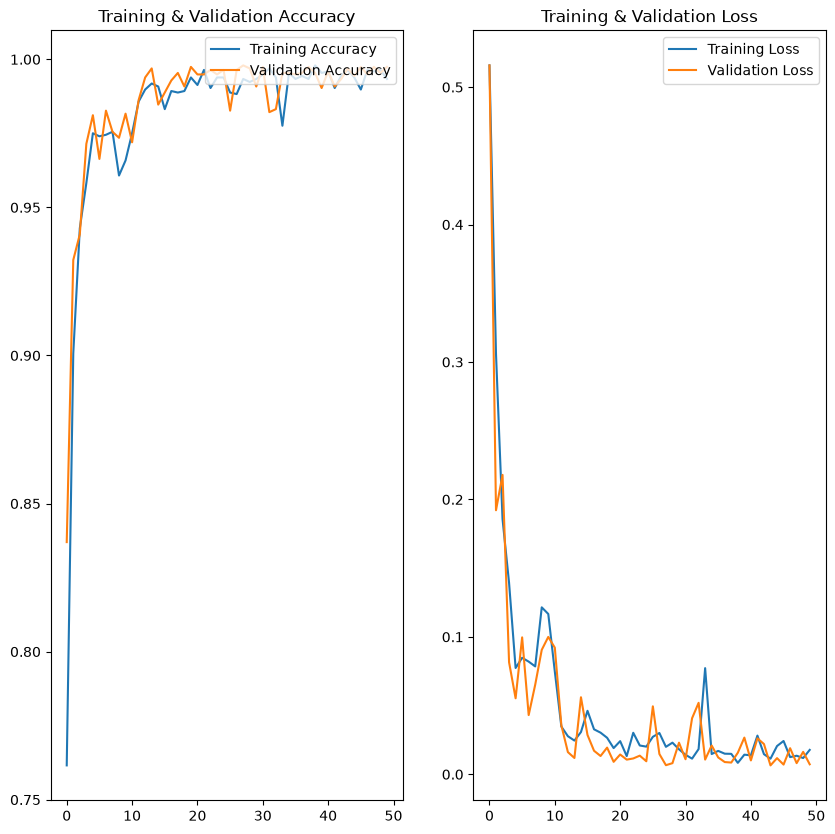

In [27]:
plt.figure(figsize=(10, 10))

plt.subplot(1, 2, 1)
plt.plot(range(EPOCHS), acc, label="Training Accuracy")
plt.plot(range(EPOCHS), val_acc, label="Validation Accuracy")
plt.legend(loc="upper right")
plt.title("Training & Validation Accuracy")

plt.subplot(1, 2, 2)
plt.plot(range(EPOCHS), loss, label="Training Loss")
plt.plot(range(EPOCHS), val_loss, label="Validation Loss")
plt.legend(loc="upper right")
plt.title("Training & Validation Loss")

### Run prediction on a sample image

First image to predict
Actual label: Pepper__bell___healthy
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
predicted label: Pepper__bell___healthy


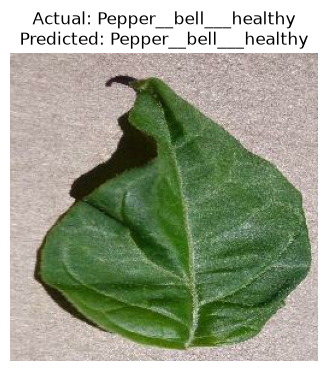

In [28]:
import numpy as np
for images_batch, labels_batch in test_ds.take(1):
    indices = np.random.permutation(len(images_batch))
    
    random_idx = indices[0]
    
    first_image = images_batch[random_idx].numpy().astype("uint8")
    first_label = labels_batch[random_idx].numpy()

    print("First image to predict")

    plt.figure(figsize=(4, 4))
    plt.imshow(first_image)
    plt.axis("off")

    actual_class = class_names[first_label]
    print(f"Actual label: {actual_class}")

    batch_prediction = model.predict(images_batch)
    predicted_class = class_names[np.argmax(batch_prediction[random_idx])]
    print(f"predicted label: {predicted_class}")

    plt.title(f"Actual: {class_names[first_label]}\nPredicted: {predicted_class}")

    plt.show()

### Inference

In [29]:
def predict(model, img):
    img_array = tf.keras.preprocessing.image.img_to_array(images[i].numpy())
    img_array = tf.expand_dims(img_array, 0)

    predictions = model.predict(img_array)
    predicted_class = class_names[np.argmax(predictions[0])]

    confidence = round(100 * (np.max(predictions[0])), 2)
    return predicted_class, confidence

### Compare predictions with actual labels and confidence

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


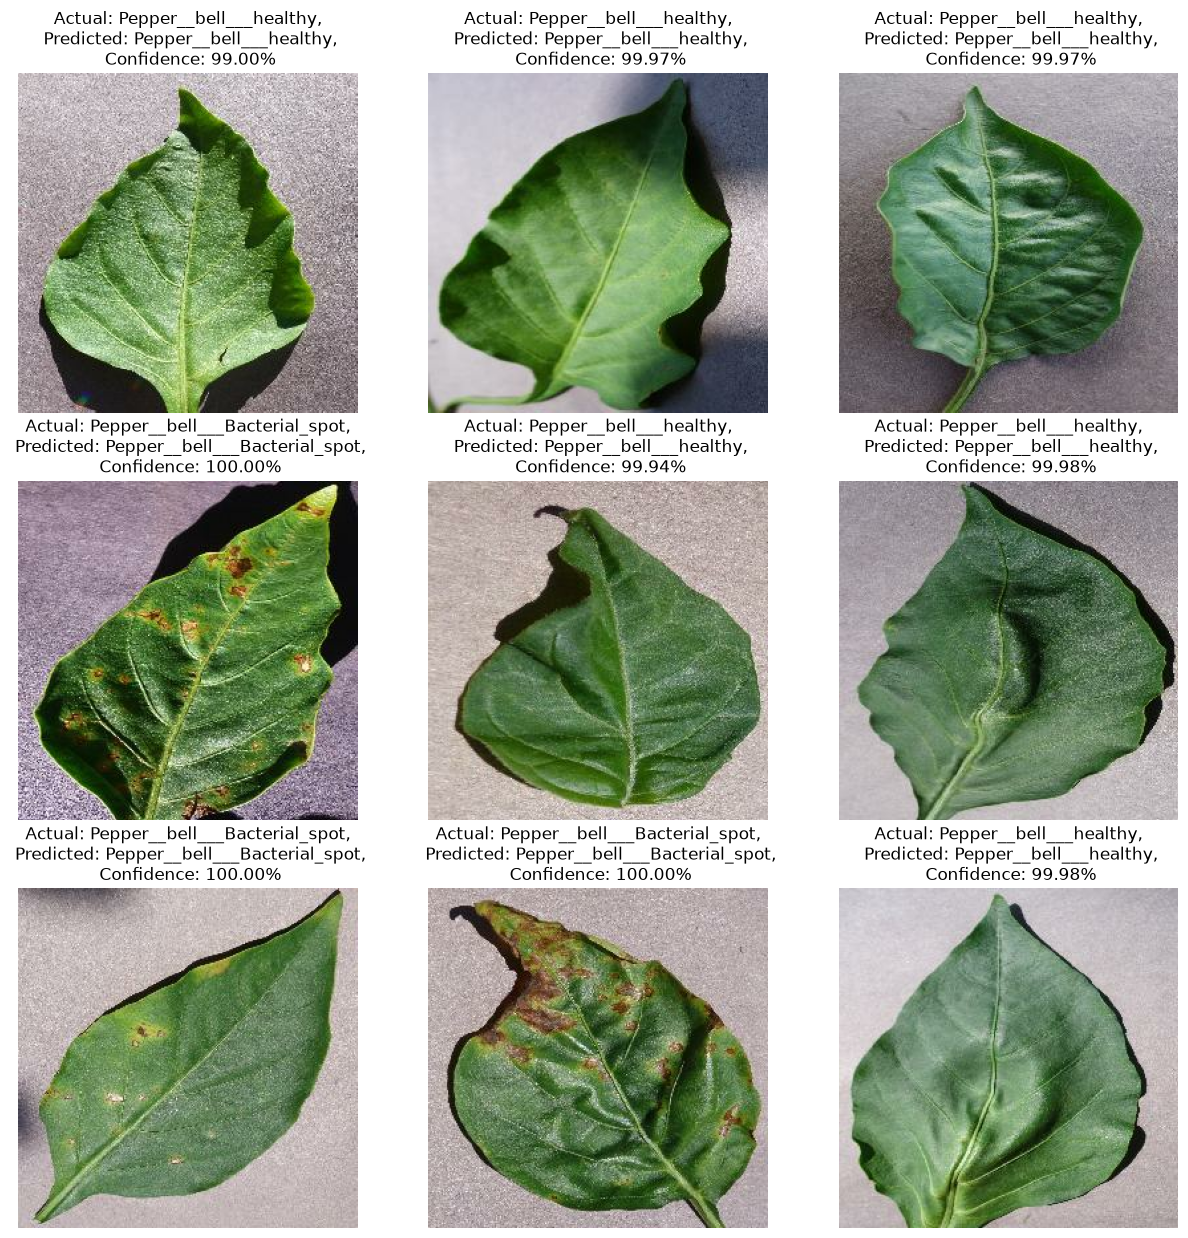

In [30]:
plt.figure(figsize=(15, 15))
for images, labels in test_ds.take(1):
    for i in range(9):
        x = plt.subplot(3, 3, i+1)
        plt.imshow(images[i].numpy().astype("uint8"))

        predicted_class, confidence = predict(model, images[i].numpy())
        actual_class = class_names[labels[i]]

        plt.title(f"Actual: {actual_class},\n Predicted: {predicted_class},\n Confidence: {confidence:.2f}%")
        plt.axis("off")

### Save the Model

In [31]:
model.save("bell_pepper_disease_cnn.keras")